In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### 1. Load the dataset

In [4]:
df = pd.read_csv("../data/raw/student_mental_health.csv")

In [ ]:
df.head(5)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [46]:
df.shape

(2000, 17)

### 2. Dataset Structure

In [17]:
number_of_observation = df.shape[0]
print(number_of_observation)

2000


In [18]:
number_of_features = df.shape[1]
print("\nNumber of features :", number_of_features)


Number of features : 17


In [15]:
names_of_columns = df.columns.to_list()
print(names_of_columns)

['Student_ID', 'Age', 'Gender', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Physical_Activity', 'Financial_Stress', 'Family_Support', 'Attendance_Rate', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']


In [16]:
data_types = df.dtypes
print(data_types)

Student_ID                            str
Age                                 int64
Gender                                str
Year_of_Study                       int64
Sleep_Hours                       float64
Study_Hours_Per_Week              float64
GPA                               float64
Social_Media_Hours                float64
Screen_Time_Hours                 float64
Physical_Activity                     str
Financial_Stress                  float64
Family_Support                    float64
Attendance_Rate                   float64
Part_Time_Job                         str
Diet_Quality                          str
Previous_Mental_Health_History        str
Mental_Health_Risk                    str
dtype: object


In [41]:
df.describe()

,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
count,2000.000000,2000.000000,1938.000000,2000.000000,1962.000000,1942.000000,2000.000000,1909.000000,1946.000000,1953.000000
mean,21.131500,2.630000,6.758875,19.997900,2.562503,6.013955,8.548500,5.956260,6.518345,85.080236
std,2.139275,1.316802,1.127072,5.719274,0.343993,1.153422,1.657571,1.893941,1.844639,7.224118
min,17.000000,1.000000,3.300000,2.400000,1.500000,2.100000,3.300000,1.400000,1.700000,54.400000
25%,20.000000,1.000000,6.000000,16.000000,2.320000,5.225000,7.400000,4.500000,5.100000,80.300000
50%,21.000000,2.000000,6.700000,19.800000,2.560000,6.000000,8.500000,6.100000,6.700000,85.100000
75%,23.000000,4.000000,7.600000,24.000000,2.790000,6.700000,9.700000,7.400000,8.000000,90.000000
max,29.000000,5.000000,10.000000,38.300000,3.660000,10.000000,14.000000,10.000000,9.900000,100.000000


In [48]:
df.value_counts("Mental_Health_Risk")

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

### 3. Data Quality Assessment

In [33]:
missing_values = df.isna().sum()

missing_summary = pd.DataFrame({
    "missing values" : missing_values,
    "percentage" : (missing_values / len(df)) * 100
})
print(missing_summary[missing_summary["missing values"] > 0])

                    missing values  percentage
Sleep_Hours                     62        3.10
GPA                             38        1.90
Social_Media_Hours              58        2.90
Financial_Stress                91        4.55
Family_Support                  54        2.70
Attendance_Rate                 47        2.35
Diet_Quality                    69        3.45


In [26]:
duplicated_values = df.duplicated().sum()
print("Number of duplicated :", duplicated_values)

Number of duplicated : 0


In [8]:
categorical_feature_cols = [
    col for col in df.select_dtypes(include="object").columns
    if col not in ["Student_ID", "Mental_Health_Risk"]
]

for col in categorical_feature_cols:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

print("\nTarget values:")
print(df["Mental_Health_Risk"].value_counts(dropna=False))


Gender:
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity:
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job:
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality:
Diet_Quality
Average    860
Poor       587
Good       484
NaN         69
Name: count, dtype: int64

Previous_Mental_Health_History:
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Target values:
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


C:\Users\USER\AppData\Local\Temp\ipykernel_21156\3199040354.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  col for col in df.select_dtypes(include="object").columns


In [10]:
expected_categories = {
    "Gender": ["Male", "Female", "Non-binary"],
    "Physical_Activity": ["Low", "Moderate", "High"],
    "Part_Time_Job": ["Yes", "No"],
    "Diet_Quality": ["Poor", "Average", "Good"],
    "Previous_Mental_Health_History": ["Yes", "No"],
    "Mental_Health_Risk": ["Low", "Medium", "High"]
}

for col, expected in expected_categories.items():
    if col not in df.columns:
        print(f"\n{col}: column not found")
        continue

    observed = set(df[col].dropna().unique())
    unexpected = observed - set(expected)

    print(f"\n--- {col} ---")
    print("Observed values:", sorted(observed))
    print("Missing values:", df[col].isna().sum())
    print("Unexpected values:", unexpected if unexpected else "None")


--- Gender ---
Observed values: ['Female', 'Male', 'Non-binary']
Missing values: 0
Unexpected values: None

--- Physical_Activity ---
Observed values: ['High', 'Low', 'Moderate']
Missing values: 0
Unexpected values: None

--- Part_Time_Job ---
Observed values: ['No', 'Yes']
Missing values: 0
Unexpected values: None

--- Diet_Quality ---
Observed values: ['Average', 'Good', 'Poor']
Missing values: 69
Unexpected values: None

--- Previous_Mental_Health_History ---
Observed values: ['No', 'Yes']
Missing values: 0
Unexpected values: None

--- Mental_Health_Risk ---
Observed values: ['High', 'Low', 'Medium']
Missing values: 0
Unexpected values: None


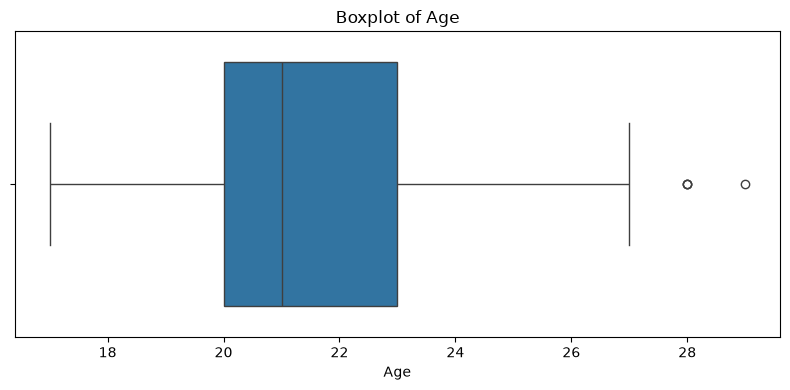

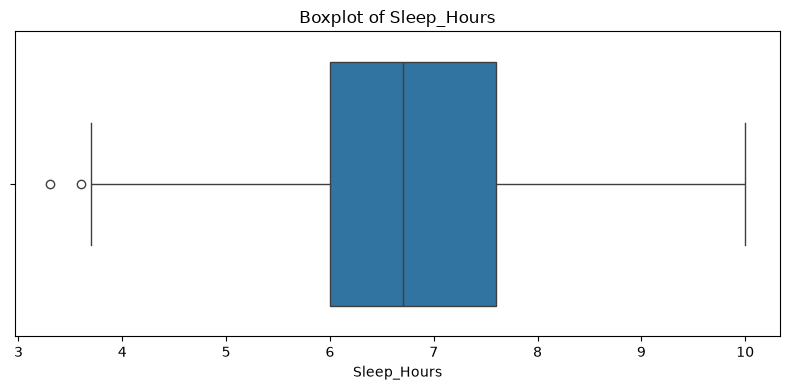

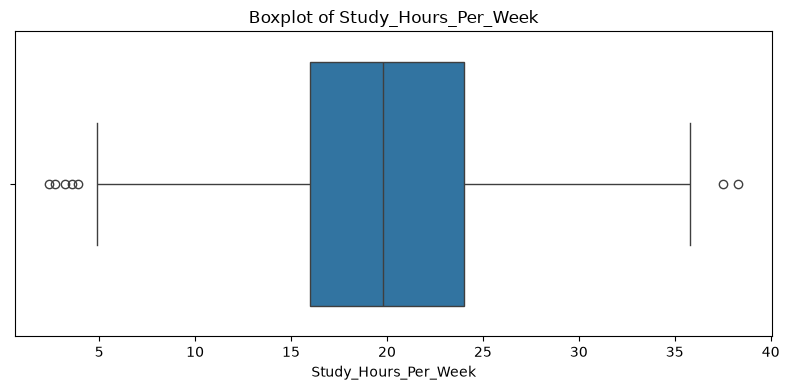

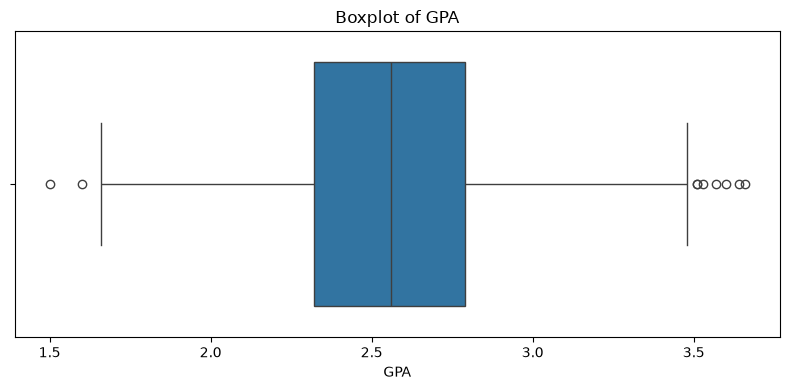

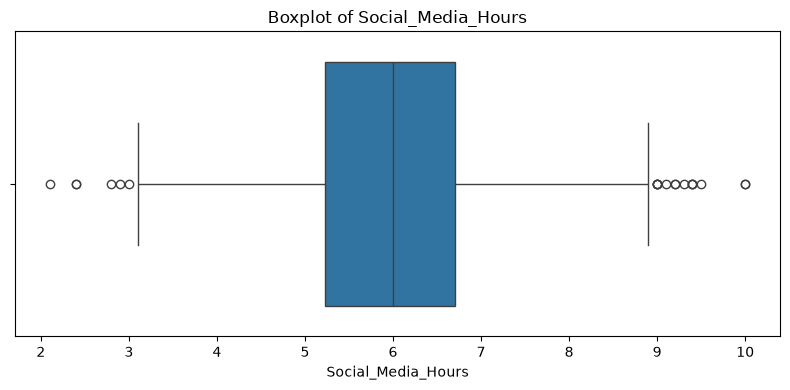

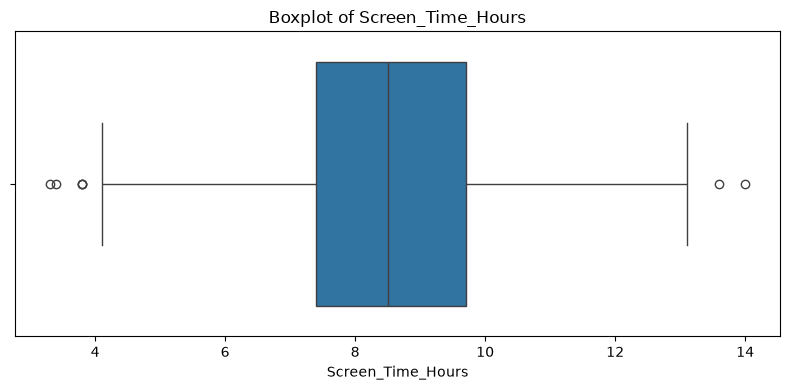

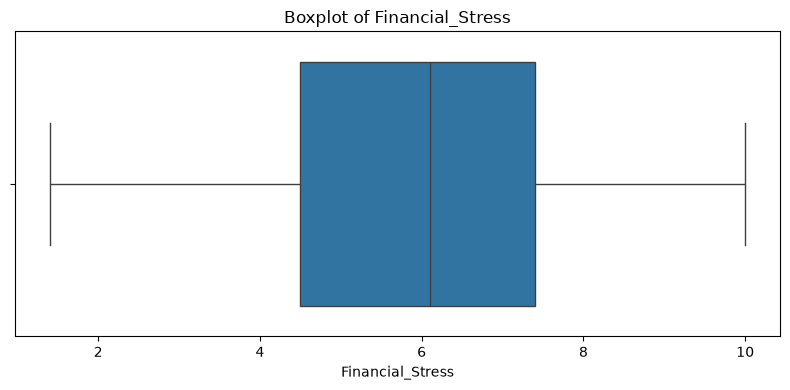

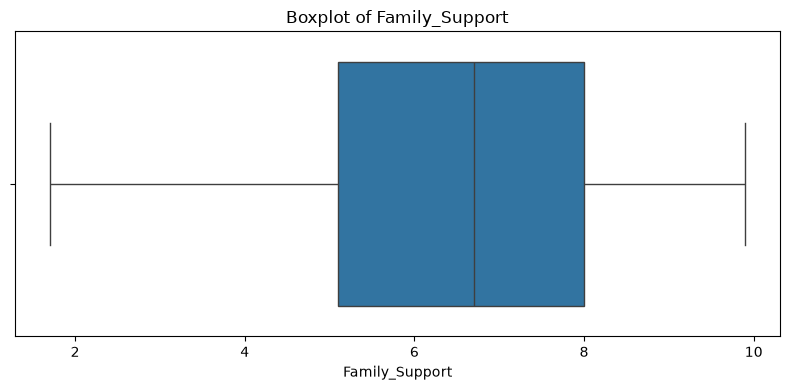

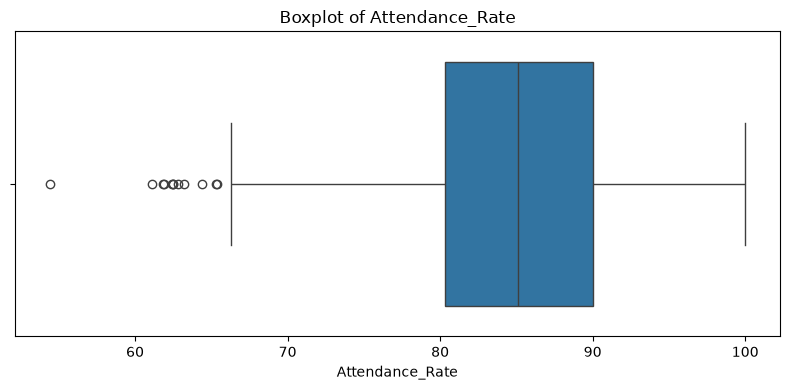

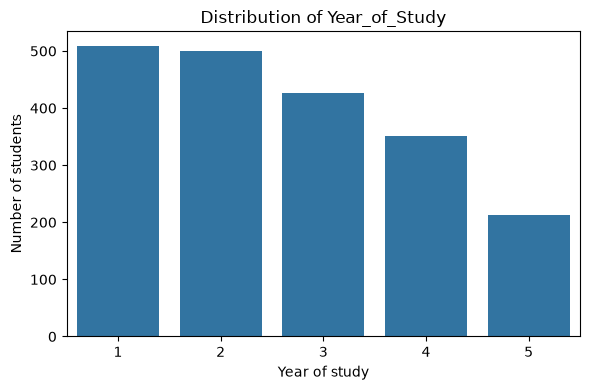

In [11]:
continuous_numeric_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col != "Year_of_Study"
]

for col in continuous_numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Year_of_Study", order=sorted(df["Year_of_Study"].dropna().unique()))
plt.title("Distribution of Year_of_Study")
plt.xlabel("Year of study")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

In [12]:
def detect_outliers_iqr(df, columns):
    outliers = {}

    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        mask = (
            (df[col] < lower_bound) |
            (df[col] > upper_bound)
        )

        outliers[col] = mask.sum()

        print(f"\nColumn: {col}")
        print(f"Lower Bound: {lower_bound}")
        print(f"Upper Bound: {upper_bound}")
        print(f"Number of outliers: {mask.sum()}")

    return outliers

outlier_summary = detect_outliers_iqr(df, continuous_numeric_cols)
outlier_summary


Column: Age
Lower Bound: 15.5
Upper Bound: 27.5
Number of outliers: 4

Column: Sleep_Hours
Lower Bound: 3.6000000000000005
Upper Bound: 10.0
Number of outliers: 2

Column: Study_Hours_Per_Week
Lower Bound: 4.0
Upper Bound: 36.0
Number of outliers: 7

Column: GPA
Lower Bound: 1.6149999999999995
Upper Bound: 3.495
Number of outliers: 9

Column: Social_Media_Hours
Lower Bound: 3.012499999999999
Upper Bound: 8.912500000000001
Number of outliers: 20

Column: Screen_Time_Hours
Lower Bound: 3.950000000000002
Upper Bound: 13.149999999999999
Number of outliers: 7

Column: Financial_Stress
Lower Bound: 0.14999999999999947
Upper Bound: 11.75
Number of outliers: 0

Column: Family_Support
Lower Bound: 0.7499999999999991
Upper Bound: 12.350000000000001
Number of outliers: 0

Column: Attendance_Rate
Lower Bound: 65.75
Upper Bound: 104.55000000000001
Number of outliers: 12


{'Age': np.int64(4),
 'Sleep_Hours': np.int64(2),
 'Study_Hours_Per_Week': np.int64(7),
 'GPA': np.int64(9),
 'Social_Media_Hours': np.int64(20),
 'Screen_Time_Hours': np.int64(7),
 'Financial_Stress': np.int64(0),
 'Family_Support': np.int64(0),
 'Attendance_Rate': np.int64(12)}

### 4. Exploratory Data Analysis — feature and target analysis

In [14]:
RISK_ORDER = ['Low', 'Medium', 'High']
RISK_CODES = {k: i for i, k in enumerate(RISK_ORDER)}

df_eda = df.copy()
df_eda['Risk_Ord'] = df_eda['Mental_Health_Risk'].map(RISK_CODES)

numeric_cols = df_eda.select_dtypes(include=np.number).columns.drop('Risk_Ord').tolist()
categorical_cols = [c for c in df_eda.select_dtypes(include='object').columns
                    if c != 'Student_ID']  # ID inutile pour l'analyse

print("Numériques :", numeric_cols)
print("Catégorielles :", categorical_cols)
print("\nOrdre cible :", RISK_ORDER)

Numériques : ['Age', 'Year_of_Study', 'Sleep_Hours', 'Study_Hours_Per_Week', 'GPA', 'Social_Media_Hours', 'Screen_Time_Hours', 'Financial_Stress', 'Family_Support', 'Attendance_Rate']
Catégorielles : ['Gender', 'Physical_Activity', 'Part_Time_Job', 'Diet_Quality', 'Previous_Mental_Health_History', 'Mental_Health_Risk']

Ordre cible : ['Low', 'Medium', 'High']


C:\Users\USER\AppData\Local\Temp\ipykernel_21156\4008543854.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = [c for c in df_eda.select_dtypes(include='object').columns


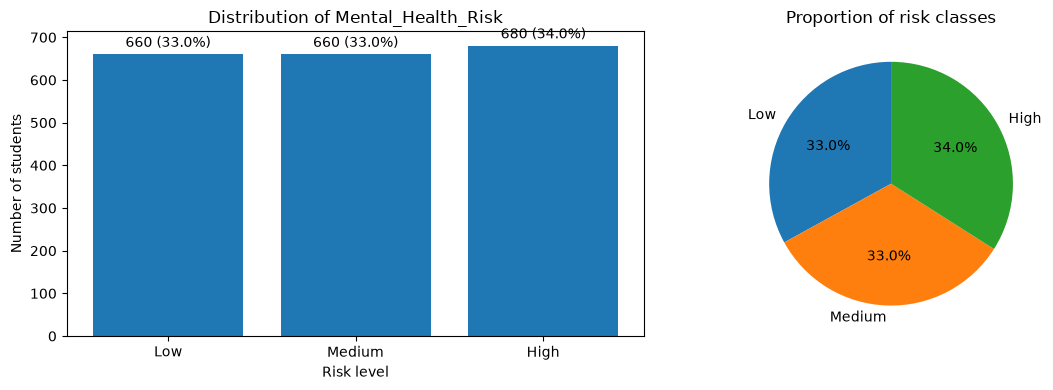

Class imbalance ratio (max/min): 1.03
Interpretation: approximately balanced


In [15]:
counts = df_eda["Mental_Health_Risk"].value_counts().reindex(RISK_ORDER, fill_value=0)
percentages = counts / counts.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bars = axes[0].bar(counts.index, counts.values)
axes[0].set_title("Distribution of Mental_Health_Risk")
axes[0].set_xlabel("Risk level")
axes[0].set_ylabel("Number of students")
axes[0].bar_label(
    bars,
    labels=[f"{n} ({p:.1f}%)" for n, p in zip(counts.values, percentages.values)],
    padding=3
)

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Proportion of risk classes")

plt.tight_layout()
plt.show()

imbalance_ratio = counts.max() / counts.min()
print(f"Class imbalance ratio (max/min): {imbalance_ratio:.2f}")
print("Interpretation: approximately balanced" if imbalance_ratio < 1.5
      else "Interpretation: class imbalance may need attention")

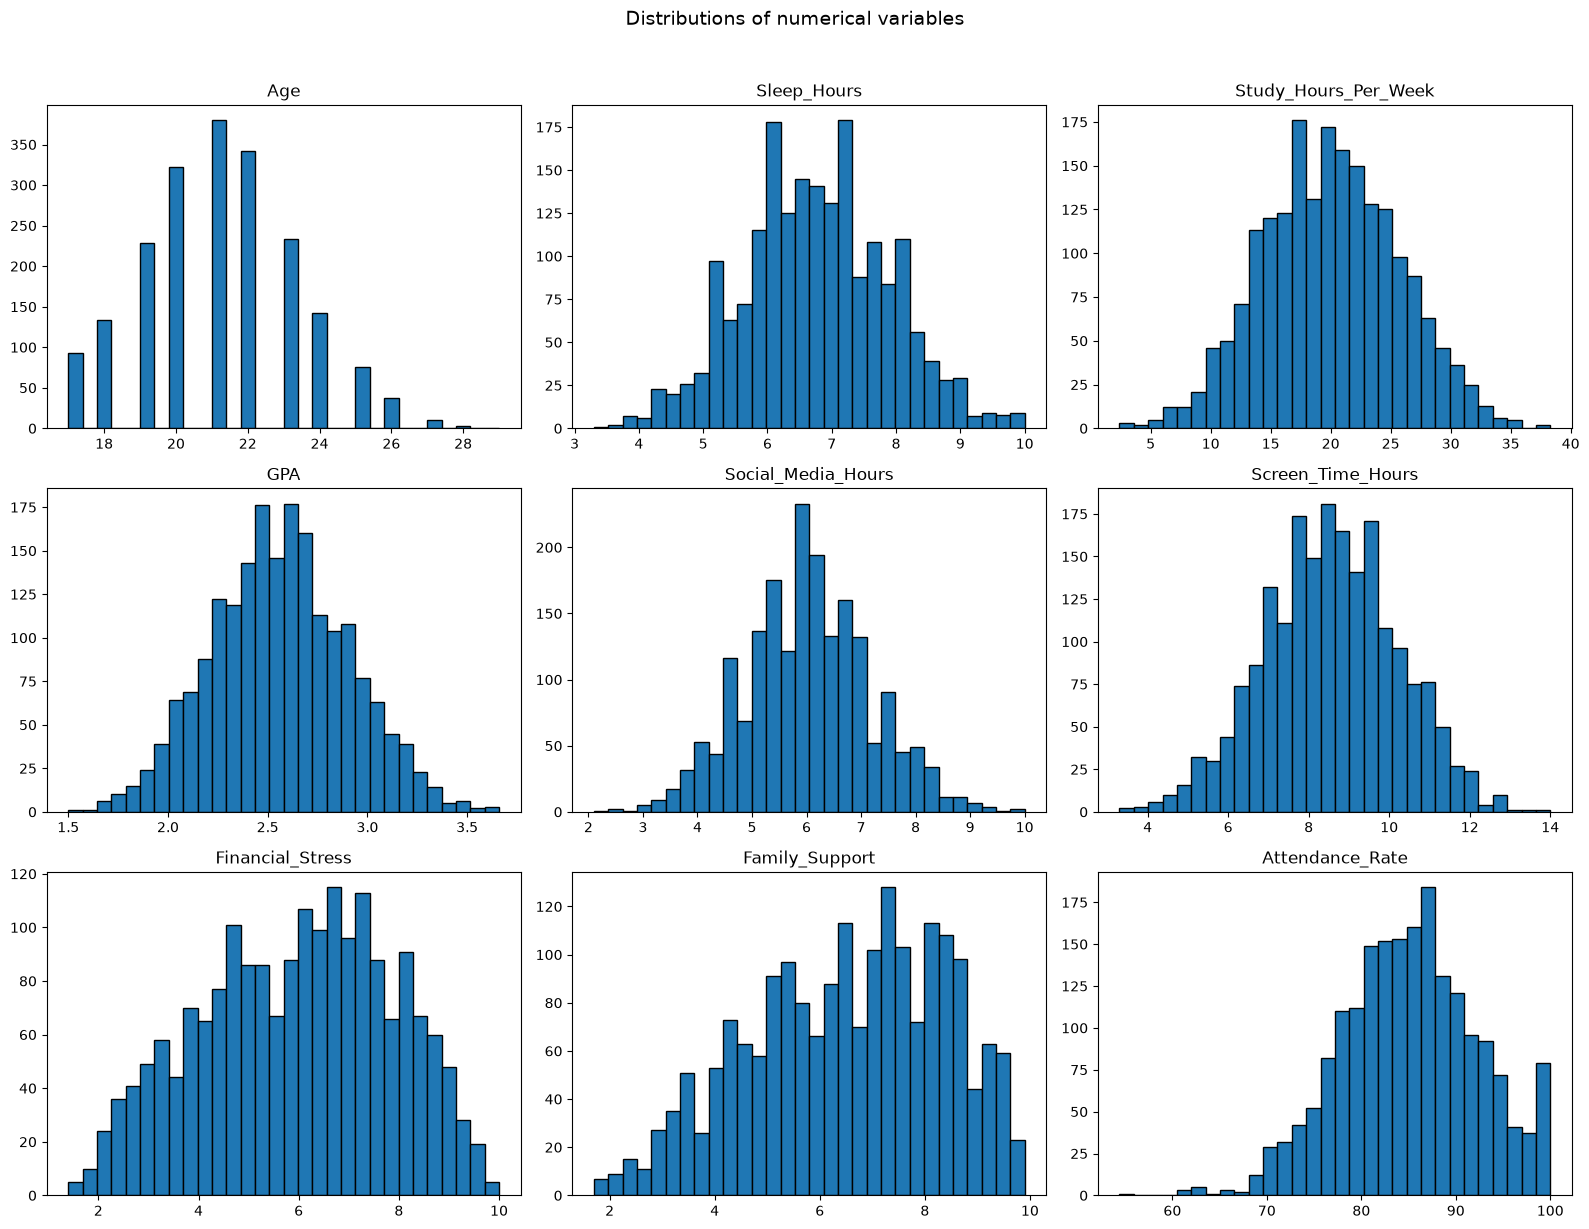

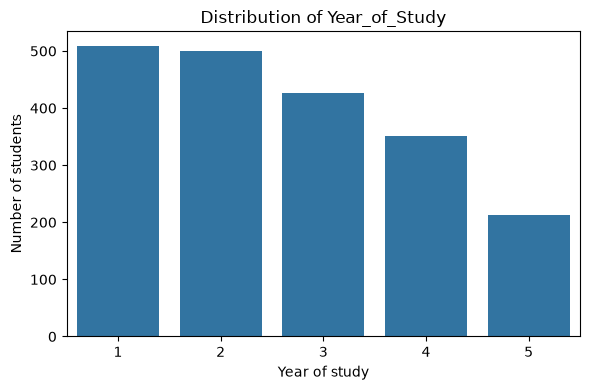

                      skewness  kurtosis
Family_Support           -0.30     -0.72
Age                       0.20     -0.18
Financial_Stress         -0.17     -0.82
Attendance_Rate          -0.12     -0.06
Social_Media_Hours        0.09      0.02
GPA                       0.09     -0.20
Sleep_Hours               0.05     -0.14
Study_Hours_Per_Week      0.04     -0.25
Screen_Time_Hours        -0.04     -0.15


In [16]:
hist_cols = [col for col in numeric_cols if col != "Year_of_Study"]

df_eda[hist_cols].hist(
    bins=30, figsize=(16, 12), edgecolor="black", grid=False
)
plt.suptitle("Distributions of numerical variables", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(data=df_eda, x="Year_of_Study", order=sorted(df_eda["Year_of_Study"].dropna().unique()))
plt.title("Distribution of Year_of_Study")
plt.xlabel("Year of study")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

skew_kurt = pd.DataFrame({
    "skewness": df_eda[hist_cols].skew(),
    "kurtosis": df_eda[hist_cols].kurt()
}).round(2).sort_values("skewness", key=abs, ascending=False)

print(skew_kurt)

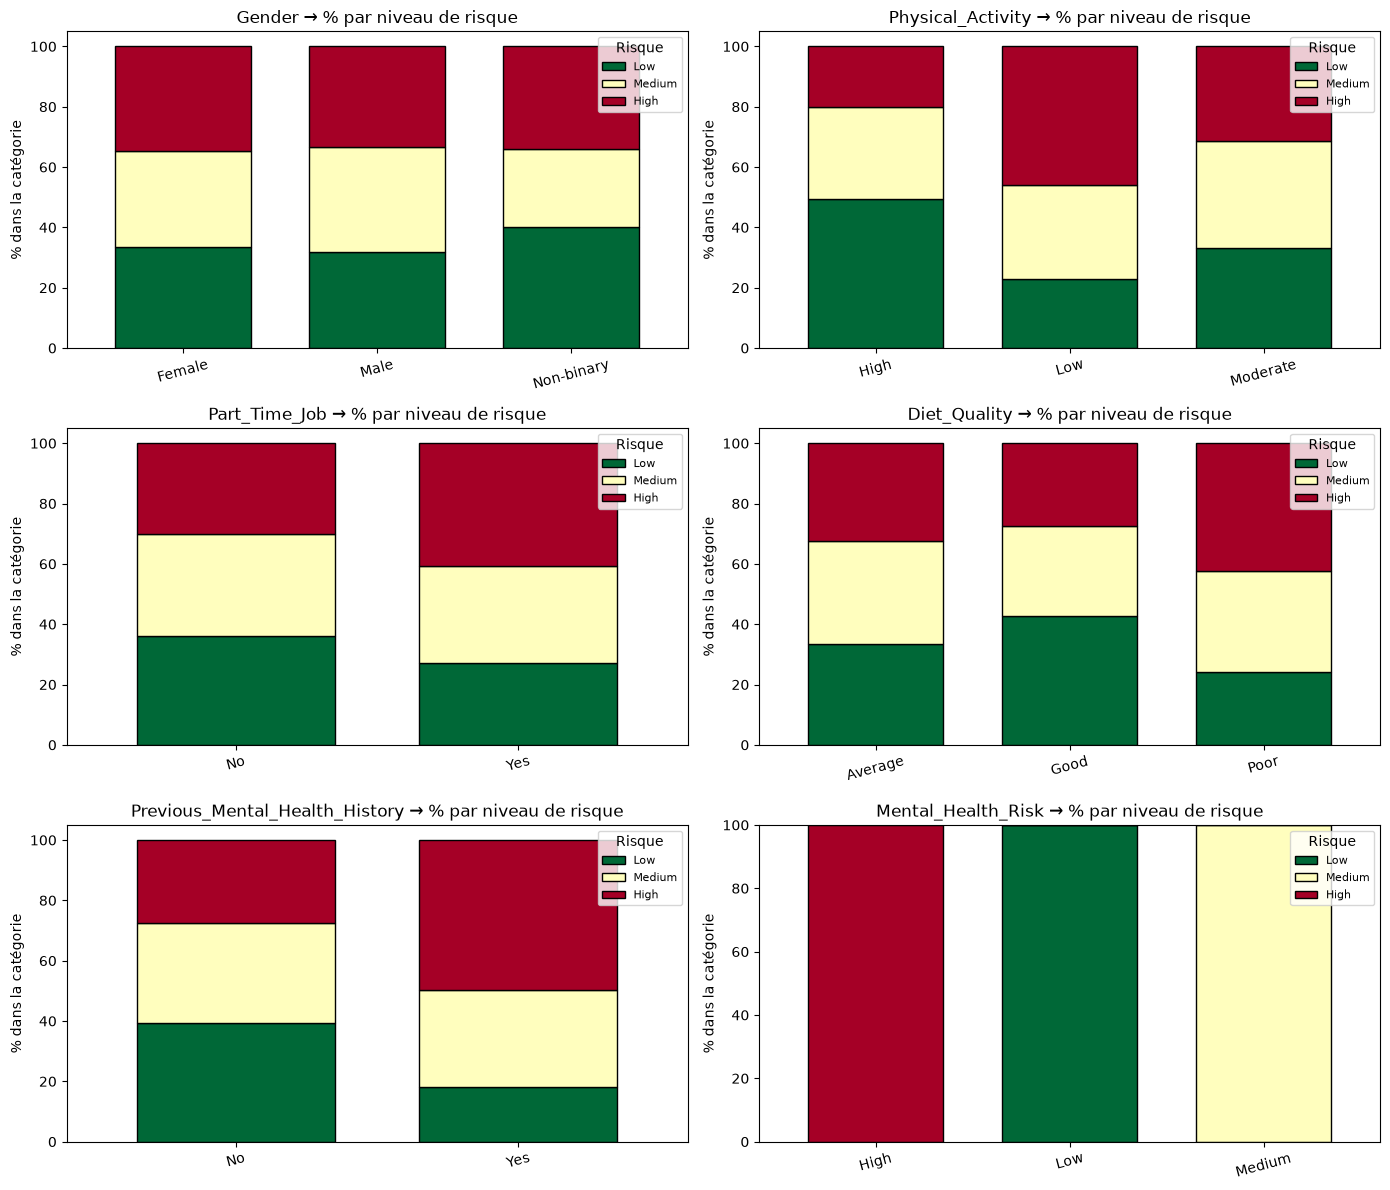

In [60]:
nrows = int(np.ceil(len(categorical_cols) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(14, 4 * nrows))

for col, ax in zip(categorical_cols, axes.flatten()):
    ct = pd.crosstab(df_eda[col], df_eda['Mental_Health_Risk'], normalize='index')[RISK_ORDER] * 100
    ct.plot.bar(stacked=True, ax=ax, colormap='RdYlGn_r', edgecolor='black', width=0.7, rot=15)
    ax.set(title=f'{col} → % par niveau de risque', ylabel='% dans la catégorie', xlabel='')
    ax.legend(title='Risque', fontsize=8, loc='upper right')

# Hide any remaining empty subplots
for ax in axes.flatten()[len(categorical_cols):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

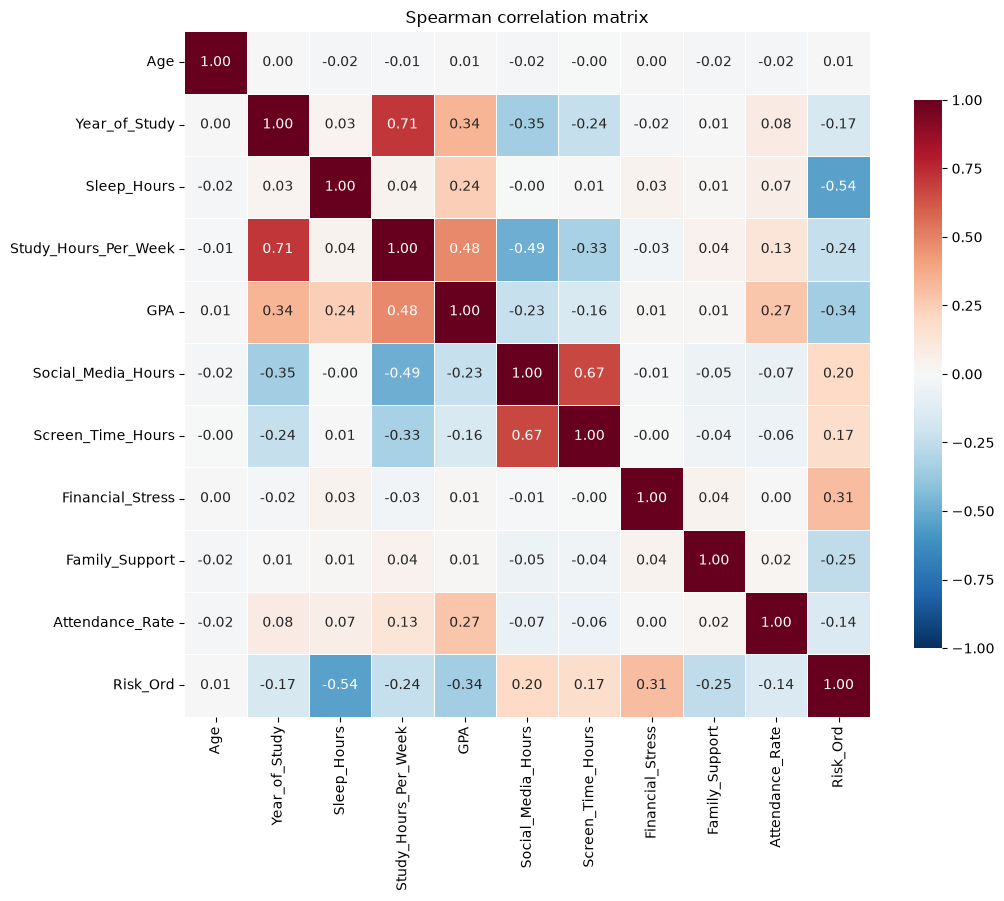

In [18]:
corr_cols = numeric_cols + ["Risk_Ord"]
corr = df_eda[corr_cols].corr(method="spearman")

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.5, cbar_kws={"shrink": 0.8}
)
plt.title("Spearman correlation matrix")
plt.tight_layout()
plt.show()